**Innovation Management · A.Y. 2026/27 · Politecnico di Torino** · Tutorial 3, notebook 1 of 2

| | |
|---|---|
| **Goal** | Collect the citations of a sector from PATSTAT, step by step from `TLS201` to `TLS212`, and draw citation networks between patents and between firms. Know the other sources of citation data: the OECD Citations database, the OECD Patent Quality Indicators and the patent-to-paper citations of *Reliance on Science*. |
| **Before this** | Tutorial 1 (patent attributes), the lecture on knowledge spillovers |
| **Time** | 45 min |
| **PATSTAT environment** | PROD (the sector is tiny, so the queries are fast; on TEST almost no citation would link two patents of the sample) |

← [Tutorial 2 · Encoding patent text](../tutorial_2/21_encoding_patent_text.ipynb) &nbsp;|&nbsp; [Back to the README](../README.md) &nbsp;|&nbsp; 31 · Measuring knowledge spillovers →

# Collecting patent citations

In the lecture about knowledge spillovers we saw that patent citations leave a **paper trail** of knowledge flows: when patent Y cites patent X, X is a piece of earlier knowledge on which Y builds. In this notebook we collect that trail for a small sector and turn it into a network. 

1. define a tiny sector with one CPC code;
2. go from its **applications** (`TLS201`) to their **publications** (`TLS211`);
3. read the **citations** made by those publications (`TLS212`), and bring them back to each application;
4. draw two **networks** with the citations made by applicants: between patents, and between the main firms;
5. see what the **category** of a citation (`TLS215`) tells us, and what it does not;
6. look at the citations received (**forward** citations): an example, and how soon a patent is first cited;
7. look at citations to **science** (`TLS214`);
8. meet three other sources of citation data, ready to use.

### Why only EP patents

**Citation practices differ across patent offices, so mixing offices mixes different things.**

- At the **USPTO** applicants have a **duty of candor**: they must disclose every piece of prior art they know to be material, or the patent can be declared unenforceable for inequitable conduct. US patents therefore carry long lists of citations added by applicants and attorneys, many for legal safety (the "super-citers" of the lecture).
- At the **EPO** there is no such duty. Most citations come from the **examiner's search report**, and each one gets a **category** (X, Y, A...) that says how relevant it is for novelty and inventive step.

So we take as **citing** documents only publications of the EPO (`publn_auth = 'EP'`). The **cited** documents can come from any office: an EP examiner can cite a US, Japanese or German patent.

## 1. Setup

All imports in one cell. If `networkx` is missing in your environment, run `%pip install -q networkx` once and restart the kernel.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from pathlib import Path
from sqlalchemy import func

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,            # applications
    TLS202_APPLN_TITLE,      # titles
    TLS206_PERSON,           # persons (applicants and inventors)
    TLS207_PERS_APPLN,       # person <-> application links
    TLS211_PAT_PUBLN,        # publications
    TLS212_CITATION,         # citations
    TLS214_NPL_PUBLN,        # non-patent literature
    TLS215_CITN_CATEG,       # citation categories
    TLS224_APPLN_CPC,        # CPC classification
)

ENV = "PROD"                 # "TEST" only to check that the code runs
patstat = PatstatClient(env=ENV)
db = patstat.orm()

OUT = Path("outputs")        # the tables we save for notebook 31
OUT.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 80)

## 2. The path through the schema

Citations do not hang on applications but on **publications**. An application is published several times (the A1 application with its search report, the B1 granted patent, corrections...), and each publication can cite other documents. So the path from a sector to its citations crosses six tables, numbered in red in the schema:

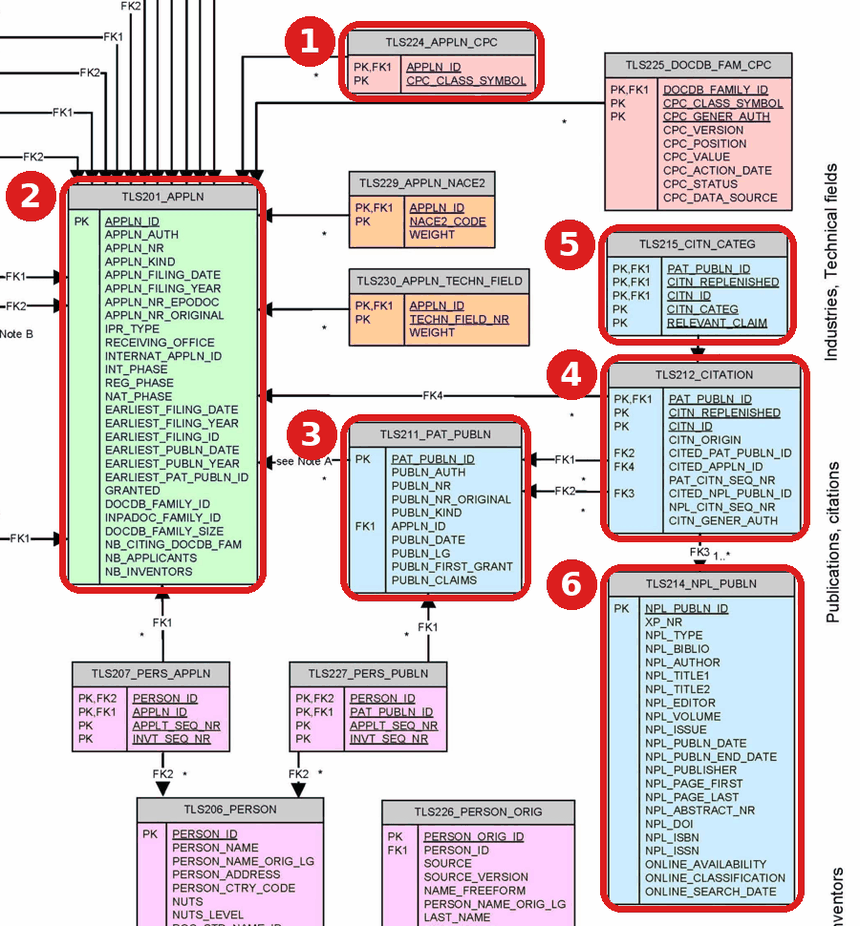

*The citation path in the PATSTAT Global schema: (1) CPC codes select the sector, (2) its applications, (3) their publications, (4) the citations those publications make, (5) the category of each citation, (6) cited non-patent literature.*

```
TLS224_APPLN_CPC ── appln_id ── TLS201_APPLN ── appln_id ── TLS211_PAT_PUBLN ── pat_publn_id ── TLS212_CITATION
   (sector)                    (applications)               (citing publications)                │
                                                                                                  ├── cited_pat_publn_id ── TLS211_PAT_PUBLN ── appln_id ── TLS201_APPLN
                                                                                                  │                         (cited publication)              (cited application, family)
                                                                                                  ├── cited_npl_publn_id ── TLS214_NPL_PUBLN (cited paper, book, web page)
                                                                                                  └── (pat_publn_id, citn_replenished, citn_id) ── TLS215_CITN_CATEG (X, Y, A...)
```

`TLS211_PAT_PUBLN` is used **twice**: once for the citing publications, once for the cited ones.

## 3. Step 1: coffee capsules and pods

We take **coffee capsules and pods**: CPC group `B65D 85/804` and its subgroups, *packages for beverages to be prepared in the package itself*. It is a small, well-defined sector with a famous story: when Nestlé's Nespresso patents expired, many firms entered with compatible capsules, and the patent fights that followed are full of citations.

These EP applications are **our sample for the whole notebook**: every table below (publications, citations, networks, forward citations, science) refers to exactly these applications (so we don't consider US applications, for instance).

As in Tutorial 1, we remove the blanks from `cpc_class_symbol` before matching, so that `B65D 85/804` and `B65D  85/8043` are written the same way.

In [3]:
CPC_PREFIX = "B65D85/804"    # coffee capsules and pods; you can change to your PW sector :)
YEARS = (2000, 2022)         # filing years of the EP applications we keep

symbol = func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "")

# The EP applications of the sector: these are our citing documents
q = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_filing_date,
        TLS201_APPLN.appln_filing_year,
        TLS201_APPLN.granted,
    )
    .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    .filter(symbol.like(CPC_PREFIX + "%"))
    .filter(TLS201_APPLN.appln_auth == "EP")
    .filter(TLS201_APPLN.appln_filing_year.between(*YEARS))
    .distinct()
)
ep = patstat.df(q)
ep["appln_filing_date"] = pd.to_datetime(ep.appln_filing_date, errors="coerce")

# Our sample: the list of appln_id used in every query of the notebook
SAMPLE = [int(i) for i in ep.appln_id]
print(f"Our sample: {len(SAMPLE):,} EP applications filed {YEARS[0]}-{YEARS[1]}")
ep.head()

Our sample: 1,410 EP applications filed 2000-2022


,appln_id,docdb_family_id,appln_filing_date,appln_filing_year,granted
0,16395249,8185271,2003-01-13,2003,Y
1,468705933,54010919,2016-08-22,2016,Y
2,323247582,43108425,2010-08-20,2010,N
3,476506607,48703583,2013-07-01,2013,Y
4,335743361,42983594,2011-06-30,2011,N


Every query below keeps only the applications of our sample. We write the filter once, in a small function: it takes a query and the column that holds the `appln_id`, and keeps the rows whose `appln_id` is in `SAMPLE`.

In [4]:
def in_sample(query, appln_id_col):
    """Keep only the applications of our sample."""
    return query.filter(appln_id_col.in_(SAMPLE))

Who files in this sector? We take the first applicant of each EP application (`applt_seq_nr = 1`) and its harmonised name `psn_name`. We will use these names to colour the network.

In [5]:
q = in_sample(
    db.query(TLS207_PERS_APPLN.appln_id, TLS206_PERSON.psn_name, TLS206_PERSON.person_ctry_code)
    .select_from(TLS207_PERS_APPLN)
    .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr == 1),
    TLS207_PERS_APPLN.appln_id,
).distinct()
applicants = patstat.df(q).drop_duplicates("appln_id")
ep = ep.merge(applicants, on="appln_id", how="left")

ep.psn_name.value_counts().head(10)

psn_name
NESTEC                       144
KONINKLIJKE DOUWE EGBERTS    128
NESTLE                       126
K-FEE SYSTEM                  52
KRAFT FOODS R & D             36
FREEZIO                       30
LUIGI LAVAZZA                 28
DELICA                        26
TCHIBO                        21
TUTTOESPRESSO                 20
Name: count, dtype: int64

## 4. Step 2: from applications to publications (`TLS211_PAT_PUBLN`)

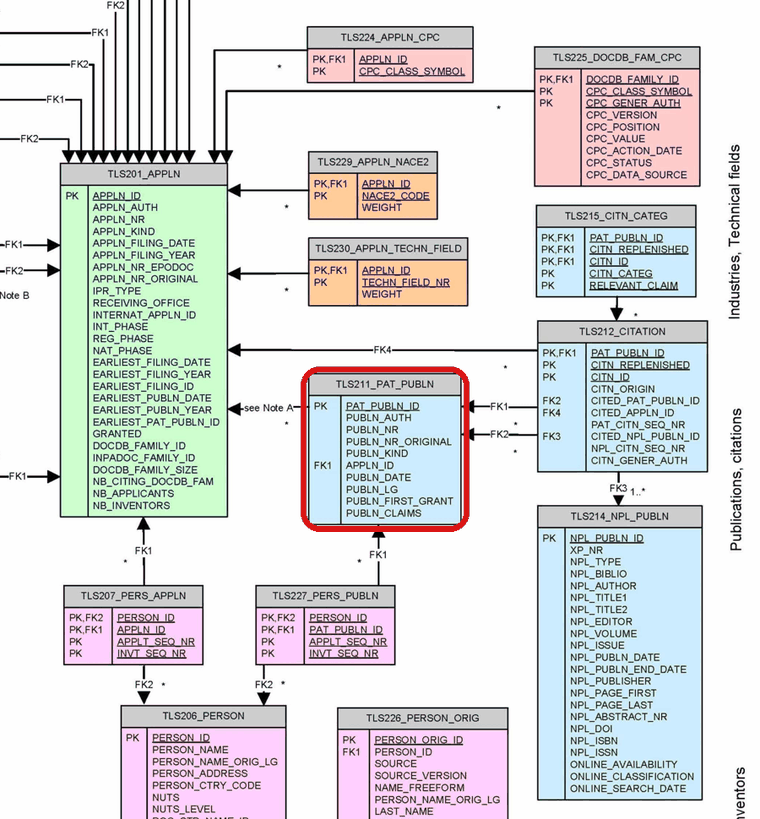

*TLS211_PAT_PUBLN: one row per publication; appln_id links it to its application.*

| Attribute | Meaning |
|---|---|
| `pat_publn_id` | Technical key of the publication. It is the key `TLS212` uses for both the citing and the cited document. Values from 900 000 001 are **artificial** publications |
| `publn_auth`, `publn_nr`, `publn_kind` | Office, number and kind code: `EP1234567A1` is office EP, number 1234567, kind A1. |
| `publn_kind` | At the EPO: `A1` application with search report, `A2` without, `A3` search report published later, `B1` granted patent, `B2` amended after opposition. |
| `publn_date` | Publication date (`9999-12-31` if unknown). |
| `publn_first_grant` | `Y` for the publication that first announces the grant. |

In [6]:
q = in_sample(
    db.query(
        TLS211_PAT_PUBLN.pat_publn_id,
        TLS211_PAT_PUBLN.appln_id,
        TLS211_PAT_PUBLN.publn_auth,
        TLS211_PAT_PUBLN.publn_nr,
        TLS211_PAT_PUBLN.publn_kind,
        TLS211_PAT_PUBLN.publn_date,
        TLS211_PAT_PUBLN.publn_first_grant,
    ).select_from(TLS211_PAT_PUBLN),
    TLS211_PAT_PUBLN.appln_id,
).distinct()
pubs = patstat.df(q)

print(f"{len(pubs):,} publications for {pubs.appln_id.nunique():,} EP applications")
print(pubs.publn_kind.value_counts())

# All the publications of one application
pubs[pubs.appln_id == pubs.appln_id.iloc[0]].sort_values("publn_date")

2,595 publications for 1,410 EP applications
publn_kind
A1    1259
B1     903
A2     151
A4      94
B2      65
C0      51
A3      49
B8      14
B9       6
B3       1
A9       1
A8       1
Name: count, dtype: int64


,pat_publn_id,appln_id,publn_auth,publn_nr,publn_kind,publn_date,publn_first_grant
0,410125448,339614828,EP,2645907,A1,2013-10-09,N
2054,417980329,339614828,EP,2645907,B1,2014-06-18,Y


One application, several publications. The search report, and so most citations, travels with the `A1` (or the later `A3`); citations added during opposition travel with the `B2`. This is why we collect citations from **all** the publications of an application, and then bring them back to the application.

## 5. Step 3: the citations (`TLS212_CITATION`)

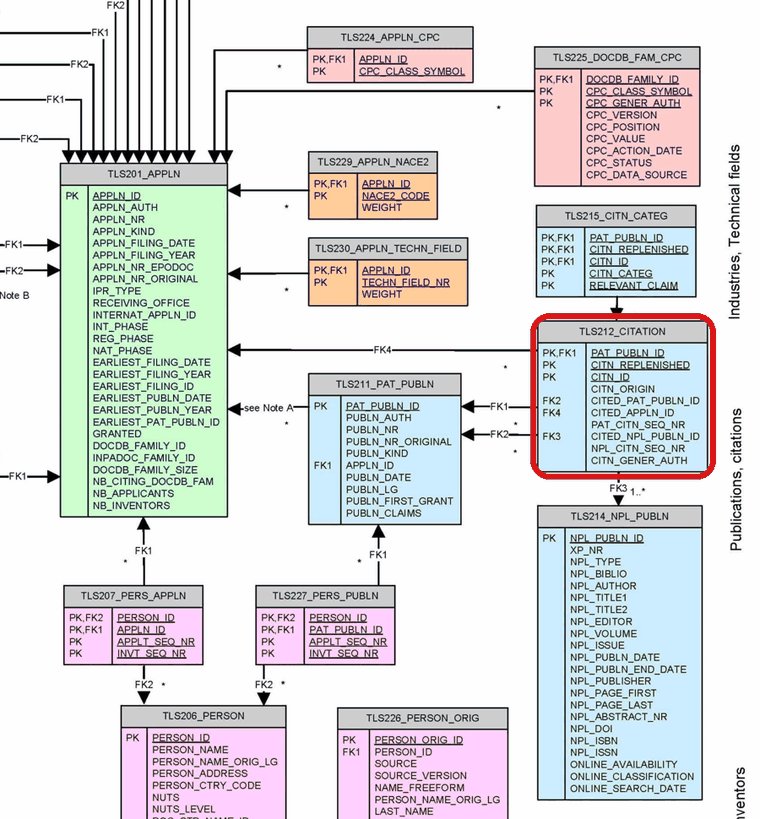

*TLS212_CITATION: one row per reference made by a citing publication (pat_publn_id).*

| Attribute | Meaning |
|---|---|
| `pat_publn_id` | The **citing** publication. |
| `citn_id`, `citn_replenished` | With `pat_publn_id`, they identify one citation; we need them to join the categories in `TLS215`. |
| `citn_origin` | **Who** added the citation, and when: `APP` applicant, `SEA` search report, `ISR` international search report (PCT), `SUP` supplementary search, `EXA` examination, `OPP`/`FOP` opposition, `TPO` third-party observations, `PRS` US pre-search. |
| `cited_pat_publn_id` | The **cited patent publication** (0 if the citation is not a patent publication). |
| `cited_appln_id` | A cited **application**, when the reference is to an application rather than to a publication (rare). |
| `cited_npl_publn_id` | A cited **non-patent document** (article, book, web page): it points to `TLS214`. |
| `citn_gener_auth` | The office that produced the search report. |

The catalog distinguishes three cases, using these columns:

| | patent publication | patent application | non-patent literature |
|---|---|---|---|
| `cited_pat_publn_id` | > 0 | 0 | 0 (or > 0 if a patent is "hidden" in the NPL reference) |
| `cited_appln_id` | 0 | > 0 | 0 |
| `cited_npl_publn_id` | 0 | 0 | > 0 |

We keep the citations of patent publications (`cited_pat_publn_id > 0`) and work in two simple steps:

1. the citations made by the publications of the sector: one row per citation, with the id of the cited publication;
2. a look-up of those cited publications in `TLS211`, to know their office, date and application.

In [7]:
# 1. The citations made by the publications of the sector
q = in_sample(
    db.query(
        TLS211_PAT_PUBLN.appln_id.label("citing_appln_id"),
        TLS212_CITATION.pat_publn_id,
        TLS212_CITATION.citn_replenished,
        TLS212_CITATION.citn_id,
        TLS212_CITATION.citn_origin,
        TLS212_CITATION.cited_pat_publn_id,
    )
    .select_from(TLS211_PAT_PUBLN)
    .join(TLS212_CITATION, TLS212_CITATION.pat_publn_id == TLS211_PAT_PUBLN.pat_publn_id)
    .filter(TLS212_CITATION.cited_pat_publn_id > 0),
    TLS211_PAT_PUBLN.appln_id,
).distinct()
back = patstat.df(q)

# 2. Look up the cited publications: office, date and application
cited_ids = [int(i) for i in back.cited_pat_publn_id.unique()]
q = db.query(
    TLS211_PAT_PUBLN.pat_publn_id.label("cited_pat_publn_id"),
    TLS211_PAT_PUBLN.publn_auth.label("cited_auth"),
    TLS211_PAT_PUBLN.publn_date.label("cited_date"), #publication date, you can still use other dates here
    TLS211_PAT_PUBLN.appln_id.label("cited_appln_id"),
).filter(TLS211_PAT_PUBLN.pat_publn_id.in_(cited_ids))
back = back.merge(patstat.df(q), on="cited_pat_publn_id", how="left")

print(f"{len(back):,} patent citations made by {back.citing_appln_id.nunique():,} EP applications")
back.head()

12,760 patent citations made by 1,408 EP applications


,citing_appln_id,pat_publn_id,citn_replenished,citn_id,citn_origin,cited_pat_publn_id,cited_auth,cited_date,cited_appln_id
0,940,941,0,5,SEA,283639226,WO,2005-07-21,24033469
1,940,941,0,1,SEA,322324822,GB,1971-12-08,22640145
2,940,941,0,3,SEA,327161464,US,1959-08-18,49340747
3,940,941,0,4,SEA,288143328,US,2002-10-10,47699043
4,940,941,0,2,SEA,305153543,FR,1989-01-06,20295489


### 5.1 One application, several publications: the same citations?

An application has several publications (section 4), and each one can carry citations. Do they cite the same documents? We take an application whose **A** publication (the application with the search report) and **B** publication (the granted patent) both carry citations, and put the two lists side by side: one row per cited publication, one column per citing publication, with the origin of the citation.

In [8]:
kinds = back.merge(pubs[["pat_publn_id", "publn_kind"]], on="pat_publn_id", how="left")
kinds["letter"] = kinds.publn_kind.str[0]

# Applications with citations on both an A and a B publication
both = kinds.groupby("citing_appln_id").letter.agg(lambda s: {"A", "B"} <= set(s))
example = both[both].index[0] if both.any() else kinds.citing_appln_id.iloc[0]
ex = kinds[kinds.citing_appln_id == example]

print(f"Application {example}: {ex.pat_publn_id.nunique()} citing publications ({', '.join(sorted(ex.publn_kind.unique()))})")
side_by_side = ex.pivot_table(index=["cited_pat_publn_id", "cited_auth"], columns="publn_kind",
                              values="citn_origin", aggfunc=lambda s: ", ".join(sorted(set(s))))
side_by_side.fillna("")

Application 172734: 2 citing publications (A2, B1)


,publn_kind,A2,B1
cited_pat_publn_id,cited_auth,,
283658330,US,"APP, ISR",
286242713,WO,"APP, ISR",
290525063,WO,APP,
295272597,US,APP,
296198710,EP,APP,
305127982,US,,EXA
316135195,EP,APP,
337393574,EP,APP,


In [9]:
# Are the lists the same?
lists = ex.groupby("publn_kind").cited_pat_publn_id.apply(set)
a_kind = [k for k in lists.index if k.startswith("A")][0]
b_kind = [k for k in lists.index if k.startswith("B")][0] if any(k.startswith("B") for k in lists.index) else None
if b_kind:
    common = lists[a_kind] & lists[b_kind]
    print(f"Cited in {a_kind}: {len(lists[a_kind])} · cited in {b_kind}: {len(lists[b_kind])} · in both: {len(common)}")
    print(f"Only in {a_kind}: {len(lists[a_kind] - lists[b_kind])} · only in {b_kind}: {len(lists[b_kind] - lists[a_kind])}")

Cited in A2: 7 · cited in B1: 1 · in both: 0
Only in A2: 7 · only in B1: 1


The lists are usually **not** the same. The A publication carries the citations of the **search report** (`SEA`, `ISR`) and those of the applicant (`APP`); the B publication repeats the applicant's references and adds those that came up during **examination** (`EXA`) or **opposition** (`OPP`, `FOP`). No single publication has the full list.

### 5.2 All the citations of each application

So for each application we take the **union** of the documents cited by **all** its publications, and count each cited publication once.

In [10]:
app_cites = back.drop_duplicates(["citing_appln_id", "cited_pat_publn_id"])
per_app = app_cites.groupby("citing_appln_id").cited_pat_publn_id.nunique()

print(f"Rows in TLS212 for our sample:            {len(back):,}")
print(f"Distinct (application, cited publication): {len(app_cites):,}")
print(f"Applications with at least one citation:   {len(per_app):,} of {len(SAMPLE):,}")
per_app.describe().round(1)

Rows in TLS212 for our sample:            12,760
Distinct (application, cited publication): 11,212
Applications with at least one citation:   1,408 of 1,410


count    1408.0
mean        8.0
std         6.0
min         1.0
25%         4.0
50%         6.0
75%        10.0
max        55.0
Name: cited_pat_publn_id, dtype: float64

### 5.3 Who adds the citations?

At the EPO most citations come from the search (`SEA`); with Euro-PCT applications the international search report (`ISR`) plays the same role. Applicant citations (`APP`) are a minority, the opposite of the US.

In [11]:
origin = back.citn_origin.value_counts()
origin_share = (origin / origin.sum() * 100).round(1)
pd.DataFrame({"citations": origin, "share %": origin_share})

,citations,share %
citn_origin,,
ISR,4507,35.3
APP,3489,27.3
SEA,2479,19.4
FOP,1458,11.4
EXA,393,3.1
OPP,268,2.1
TPO,166,1.3


### 5.4 Additional checks

1. **Artificial publications.** About 2% of cited documents are not in DOCDB, so PATSTAT creates an artificial publication (`cited_pat_publn_id` from 900 000 001), with no date and an artificial application. We keep them for counting, but they have no inventors and no family.
2. **The same document cited twice.** If the applicant and the examiner cite the same document, there are two rows with two origins. To count *documents cited*, count distinct pairs (citing, cited).

A note on **families**: the examiner may cite the EP, the WO or the US publication of the same invention, which at the publication level look like three different documents. Citations can also be studied between **families** (`docdb_family_id`, or the ready-made table `TLS228_DOCDB_FAM_CITN`), where these equivalents count once. Here we stay with EP publications and applications.

In [12]:
back["artificial"] = back.cited_pat_publn_id >= 900000001
print(f"Citations to artificial publications: {back.artificial.mean():.1%}")

pairs = back[["citing_appln_id", "cited_pat_publn_id"]].drop_duplicates()
print(f"Rows in TLS212:                       {len(back):,}")
print(f"Distinct application -> publication:  {len(pairs):,}")

# Which offices do EP examiners cite?
back.drop_duplicates(["citing_appln_id", "cited_pat_publn_id"]).cited_auth.value_counts().head(10)

Citations to artificial publications: 0.1%
Rows in TLS212:                       12,760
Distinct application -> publication:  11,212


cited_auth
WO    4166
EP    2864
US    2646
DE     462
FR     292
GB     253
JP     145
CN      83
CH      73
ES      57
Name: count, dtype: int64

## 6. A first network: do the patents of the sector cite each other?

Now we keep only the citations that stay **inside** the sector: the citing application and the cited one are both in our sample. Each application is a **node**; each citation is an **arrow** from the citing application to the cited one. The network is **directed**: A citing B is not B citing A, and arrows point back in time.

We keep only the citations added by the **applicants** (`citn_origin = 'APP'`). A citation added by the examiner says that the cited patent is relevant prior art, not that the inventors knew it: it is not a trace of a knowledge flow. A citation written by the applicant is the closest we get to "the inventors knew and used this patent".

If the picture is too crowded, lower `MAX_NODES`, or narrow `YEARS` in section 3 and run again.

Citations inside the sector: 351, linking 321 of 1,410 applications


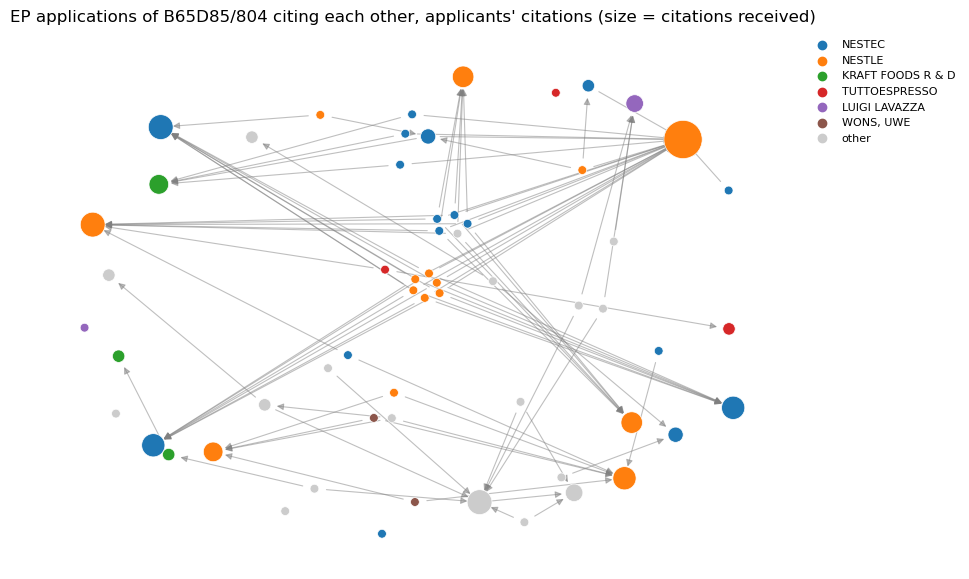

In [14]:
MAX_NODES = 60               # how many applications we draw at most
ORIGINS = ["APP"]            # citations added by the applicants

sector_ids = set(ep.appln_id)
inside = back[back.citn_origin.isin(ORIGINS) & back.cited_appln_id.isin(sector_ids)
              & (back.citing_appln_id != back.cited_appln_id)]
edges = inside[["citing_appln_id", "cited_appln_id"]].drop_duplicates()

G = nx.DiGraph()
G.add_edges_from(edges.itertuples(index=False, name=None))
print(f"Citations inside the sector: {len(edges):,}, linking {G.number_of_nodes():,} of {len(ep):,} applications")

# Draw the largest connected part; if it is too big, keep its most connected applications
part = G.subgraph(max(nx.weakly_connected_components(G), key=len)) if len(G) else G
if len(part) > MAX_NODES:
    top_nodes = sorted(part.degree, key=lambda nd: nd[1], reverse=True)[:MAX_NODES]
    part = part.subgraph([n for n, d in top_nodes])
H = nx.DiGraph(part)
pos = nx.spring_layout(H, seed=3, k=0.5)        # we keep this layout for the next pictures

firm = ep.set_index("appln_id").psn_name.reindex(list(H.nodes)).fillna("unknown")
main_firms = firm.value_counts().head(6).index
colour_of = {f: plt.cm.tab10(k) for k, f in enumerate(main_firms)}
node_colours = [colour_of.get(firm[n], (0.8, 0.8, 0.8, 1)) for n in H.nodes]
sizes = [40 + 40 * H.in_degree(n) for n in H.nodes]

fig, ax = plt.subplots(figsize=(10, 7))
nx.draw_networkx_edges(H, pos, ax=ax, alpha=0.5, arrowsize=10, width=0.8, edge_color="grey")
nx.draw_networkx_nodes(H, pos, ax=ax, node_size=sizes, node_color=node_colours, edgecolors="white", linewidths=0.5)
for f, c in colour_of.items():
    ax.scatter([], [], color=c, label=f)
ax.scatter([], [], color=(0.8, 0.8, 0.8), label="other")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, frameon=False)
ax.set_title(f"EP applications of {CPC_PREFIX} citing each other, applicants' citations (size = citations received)")
ax.axis("off")
plt.show()

Read the picture: an arrow goes from the newer application to the older one it builds on. Big nodes are the applications the rest of the sector builds on. Arrows between nodes of **different colours** are citations between different firms: knowledge flowing from one organisation to another. Arrows between nodes of the same colour are self-citations: knowledge that stays inside the firm.

In [15]:
firm_of = ep.set_index("appln_id").psn_name
e = edges.assign(citing_firm=edges.citing_appln_id.map(firm_of), cited_firm=edges.cited_appln_id.map(firm_of)).dropna()
print(f"Citations inside the sector between applications with a known applicant: {len(e):,}")
print(f"... of which within the same firm (self-citations): {(e.citing_firm == e.cited_firm).mean():.1%}")

# The most cited applications inside the sector
pd.Series(dict(G.in_degree()), name="cited_by_the_sector").sort_values(ascending=False).head(5).to_frame()   .join(ep.set_index("appln_id")[["psn_name", "appln_filing_year"]])

Citations inside the sector between applications with a known applicant: 351
... of which within the same firm (self-citations): 15.4%


,cited_by_the_sector,psn_name,appln_filing_year
16048036,52,NESTLE,2003
15995057,26,CAFFITA SYSTEM,2003
16298286,14,TCHIBO,2006
442237063,10,SWISS COFFEE INNOVATION,2015
305191768,9,NESTEC,2010


### 6.1 The same flows between firms

Patents are filed by firms, and knowledge flows between firms are what spillovers are about. We now draw the same applicants' citations with one **node per firm**, for the `TOP_N` firms with the most filings in our sample. An arrow from firm A to firm B means that A's patents cite B's patents; its width is the number of citations, its colour is the colour of the **citing** firm. Between two firms there can be two arrows, one for each direction: who learns from whom.

Firms sometimes file under several names: Nestlé files as `NESTEC` and as `NESTLE`. We merge such names first.

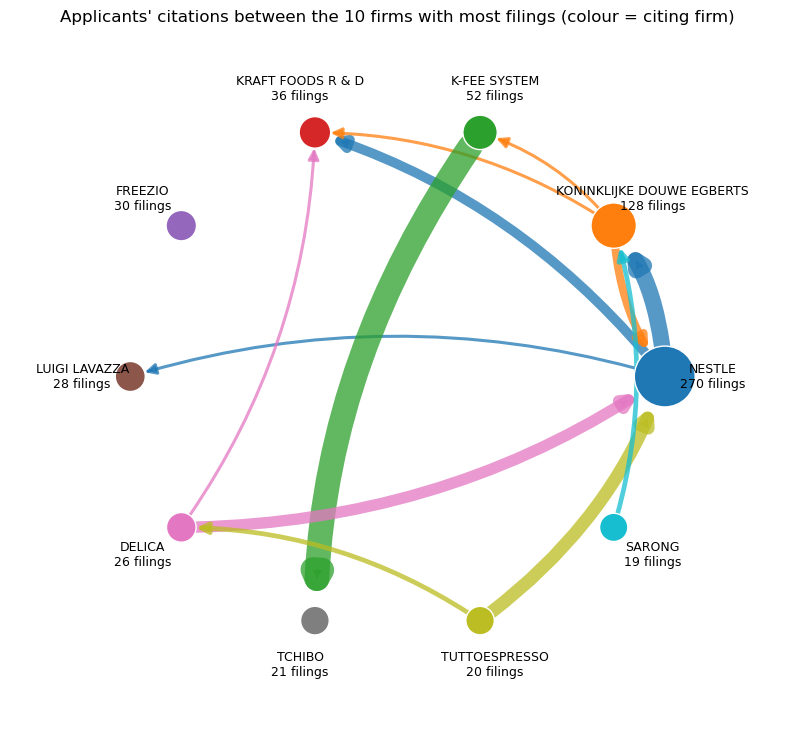

In [17]:
TOP_N = 10
SAME_GROUP = {"NESTEC": "NESTLE"}           # names that belong to the same group: remember entity linking :)

ep["firm"] = ep.psn_name.replace(SAME_GROUP)
filings = ep.firm.value_counts().head(TOP_N)
firm_of = ep.set_index("appln_id").firm

f = edges.assign(citing=edges.citing_appln_id.map(firm_of), cited=edges.cited_appln_id.map(firm_of)).dropna()
f = f[f.citing.isin(filings.index) & f.cited.isin(filings.index)]
self_cites = f[f.citing == f.cited].groupby("citing").size()
flows = f[f.citing != f.cited].groupby(["citing", "cited"]).size().rename("citations").reset_index()

F = nx.DiGraph()
F.add_nodes_from(filings.index)
F.add_weighted_edges_from(flows.itertuples(index=False, name=None))
fpos = nx.circular_layout(F)
firm_colour = {firm: plt.cm.tab10(k) for k, firm in enumerate(filings.index)}
nodes = list(F.nodes)
node_sizes = [300 + 6 * filings[n] for n in nodes]

fig, ax = plt.subplots(figsize=(10, 9))
for u, v, w in F.edges(data="weight"):
    nx.draw_networkx_edges(F, fpos, ax=ax, edgelist=[(u, v)], nodelist=nodes, node_size=node_sizes,
                           width=1 + 1.2 * w, edge_color=[firm_colour[u]], alpha=0.75, arrowsize=16,
                           connectionstyle="arc3,rad=0.15")
nx.draw_networkx_nodes(F, fpos, ax=ax, nodelist=nodes, node_size=node_sizes,
                       node_color=[firm_colour[n] for n in nodes], edgecolors="white")
for n, (x, y) in fpos.items():
    ax.text(x * 1.18, y * 1.18, f"{n}\n{filings[n]} filings", ha="center", va="center", fontsize=9)
ax.set_title(f"Applicants' citations between the {TOP_N} firms with most filings (colour = citing firm)")
ax.set_xlim(-1.45, 1.45)
ax.set_ylim(-1.35, 1.35)
ax.axis("off")
plt.show()

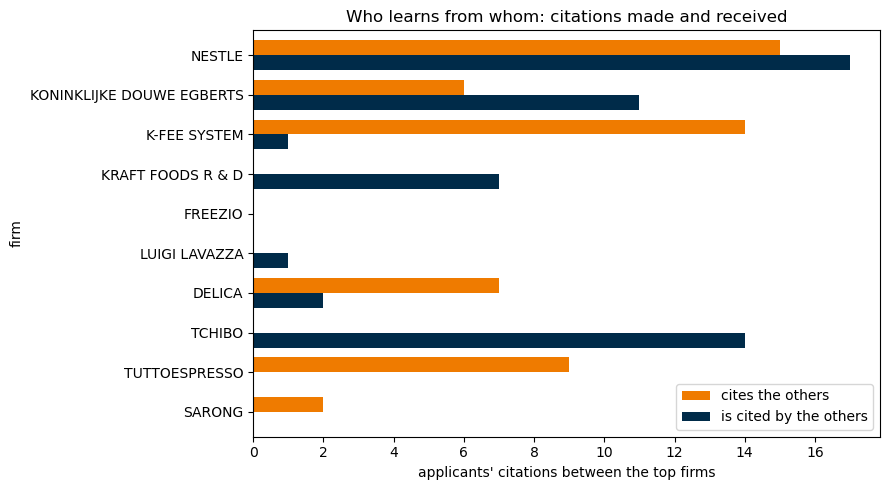

,cites the others,is cited by the others,self-citations
firm,,,
NESTLE,15,17,109
KONINKLIJKE DOUWE EGBERTS,6,11,2
K-FEE SYSTEM,14,1,5
KRAFT FOODS R & D,0,7,2
FREEZIO,0,0,0
LUIGI LAVAZZA,0,1,4
DELICA,7,2,1
TCHIBO,0,14,0
TUTTOESPRESSO,9,0,2


In [18]:
# Two flows for each firm: citations it makes to the other firms, and citations it receives from them
balance = pd.DataFrame({
    "cites the others": flows.groupby("citing").citations.sum(),
    "is cited by the others": flows.groupby("cited").citations.sum(),
    "self-citations": self_cites,
}).reindex(filings.index).fillna(0).astype(int)

ax = balance[["cites the others", "is cited by the others"]].plot.barh(
    figsize=(9, 5), color=["#EF7B00", "#002B49"], width=0.75)
ax.invert_yaxis()
ax.set_xlabel("applicants' citations between the top firms")
ax.set_title("Who learns from whom: citations made and received")
plt.tight_layout()
plt.show()

balance

A firm that **is cited** much more than it **cites** is a source of knowledge for the others; a firm that mostly cites is a follower, building on what the others found. The self-citations column shows how much each firm builds on its own earlier patents.

## 7. Step 4: the category of each citation (`TLS215_CITN_CATEG`)

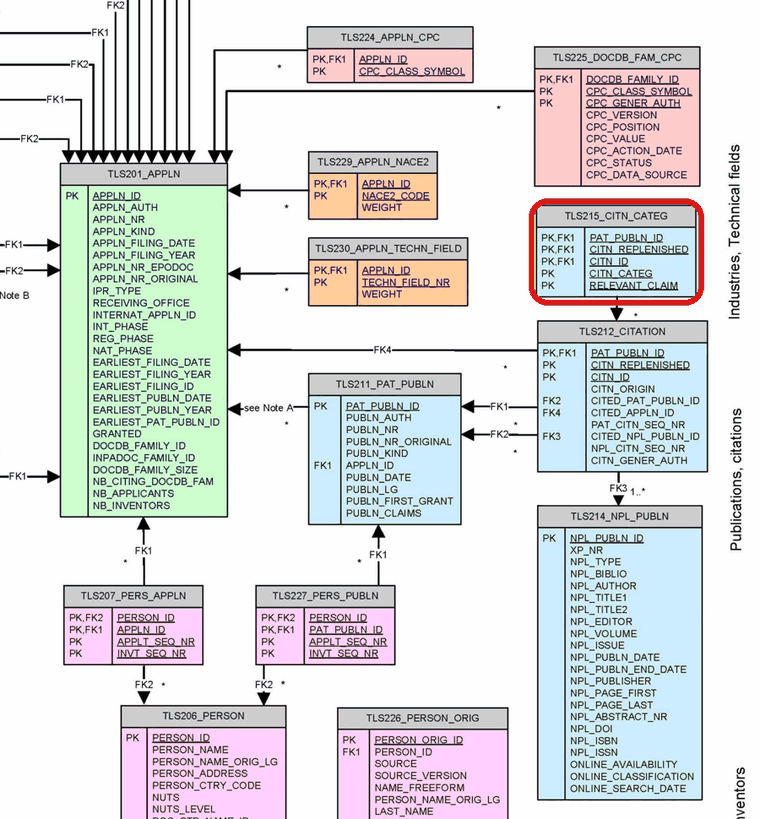

*TLS215_CITN_CATEG: one or more categories for each citation, joined on (pat_publn_id, citn_replenished, citn_id).*

Search examiners give each citation a category that says **why** the document is relevant:

| Category | Meaning |
|---|---|
| `X` | relevant on its own: the claimed invention is not new, or not inventive |
| `I` | relevant on its own for inventive step (since April 2011, split from X) |
| `Y` | relevant in combination with another document of the same category |
| `A` | general state of the art, not prejudicing novelty or inventive step |
| `D` | already cited in the application itself |
| `P` | published between the priority date and the filing date |
| `E` | earlier patent document published on or after the filing date |
| `O`, `T`, `L`, `&` | non-written disclosure, theory behind the invention, other reasons, same family |

One citation can have several letters (`XY`, `AD`, `XP`).

Categories are written by the **examiner** during the search: the check below shows that only search citations (`SEA`, `ISR`) have them. They say how close a document is to the invention for **patentability**, not whether the inventors knew it. A citation added by the examiner, whatever its category, is not a trace of knowledge flowing to the inventors, which is why our networks use only the applicants' citations.

In [19]:
q = in_sample(
    db.query(
        TLS215_CITN_CATEG.pat_publn_id,
        TLS215_CITN_CATEG.citn_replenished,
        TLS215_CITN_CATEG.citn_id,
        TLS215_CITN_CATEG.citn_categ,
    )
    .select_from(TLS215_CITN_CATEG)
    .join(TLS211_PAT_PUBLN, TLS211_PAT_PUBLN.pat_publn_id == TLS215_CITN_CATEG.pat_publn_id),
    TLS211_PAT_PUBLN.appln_id,
).distinct()
categ = patstat.df(q)

# Several rows (one per group of claims) can belong to one citation: keep all the letters once
categ["letters"] = categ.citn_categ.str.strip().apply(list)
keys = ["pat_publn_id", "citn_replenished", "citn_id"]
letters = categ.explode("letters").groupby(keys)["letters"].agg(lambda s: "".join(sorted(set(s)))).reset_index()

back = back.merge(letters, on=keys, how="left")
back["x_or_y"] = back.letters.fillna("").str.contains("[XIY]")

print(f"Citations with a category: {back.letters.notna().mean():.1%}")
back.letters.fillna("").str.split("").explode().loc[lambda s: s != ""].value_counts()

Citations with a category: 54.7%


letters
A    4012
X    2218
Y    1424
I    1078
D     517
P     113
E      38
L       2
Name: count, dtype: int64

## 8. Forward citations: who builds on the sector, and how soon?

So far we looked **backward**, at what the sector cites. Reversing the question gives the **forward** citations: the EP publications that **cite** the sector. Again two steps: in `TLS212` we look for rows whose *cited* publication is one of the sector's publications (the `pubs` table of section 4); then we look up the citing publications in `TLS211` to keep the EP ones, with their application and date. The citing publications can belong to any technology.

In [21]:
# 1. Rows of TLS212 that cite one of the sector's publications
sector_pubs = [int(i) for i in pubs.pat_publn_id.unique()]
q = db.query(
    TLS212_CITATION.pat_publn_id.label("citing_pat_publn_id"),
    TLS212_CITATION.cited_pat_publn_id,
    TLS212_CITATION.citn_origin,
).filter(TLS212_CITATION.cited_pat_publn_id.in_(sector_pubs))
fwd = patstat.df(q)

# 2. Look up the citing publications: keep the EP ones, with their application and date
citing_ids = [int(i) for i in fwd.citing_pat_publn_id.unique()]
q = db.query(
    TLS211_PAT_PUBLN.pat_publn_id.label("citing_pat_publn_id"),
    TLS211_PAT_PUBLN.appln_id.label("citing_appln_id"),
    TLS211_PAT_PUBLN.publn_date.label("citing_date"),
).filter(TLS211_PAT_PUBLN.pat_publn_id.in_(citing_ids)).filter(TLS211_PAT_PUBLN.publn_auth == "EP")
fwd = fwd.merge(patstat.df(q), on="citing_pat_publn_id")

# From the cited publication back to the cited application of the sector
fwd["cited_appln_id"] = fwd.cited_pat_publn_id.map(pubs.set_index("pat_publn_id").appln_id)
fwd = fwd[fwd.citing_appln_id != fwd.cited_appln_id]
fwd["citing_date"] = pd.to_datetime(fwd.citing_date, errors="coerce")
fwd["citing_in_sector"] = fwd.citing_appln_id.isin(sector_ids)

received = fwd.drop_duplicates(["cited_appln_id", "citing_appln_id"]).groupby("cited_appln_id").size()
print(f"EP applications citing the sector: {fwd.citing_appln_id.nunique():,}")
print(f"Sector applications cited at least once: {len(received):,} of {len(ep):,} ({len(received) / len(ep):.0%})")

EP applications citing the sector: 1,022
Sector applications cited at least once: 340 of 1,410 (24%)


### 8.1 An example: the most cited application and who cites it

We take the application of our sample cited by the largest number of EP applications and print its title. Then we look at the applications that cite it: we print their titles, and we find the **technology** each one comes from, as its main CPC class (the first three characters, such as `B65`, `A47`). The picture places the cited application at the centre and the citing ones around it, coloured and grouped by CPC class.

In [23]:
CPC_CLASS = {
    "A21": "Baking", "A23": "Foods and foodstuffs", "A24": "Tobacco", "A45": "Hand or travelling articles",
    "A47": "Furniture; domestic articles and appliances (incl. coffee machines)", "A61": "Medical or veterinary science; hygiene",
    "B01": "Physical or chemical processes in general", "B05": "Spraying; applying liquids to surfaces",
    "B08": "Cleaning", "B23": "Machine tools", "B26": "Cutting", "B29": "Working of plastics",
    "B31": "Making articles of paper or cardboard", "B32": "Layered products", "B41": "Printing",
    "B65": "Conveying; packing; storing", "B67": "Opening or closing containers; handling liquids",
    "C08": "Polymers", "C09": "Dyes; paints; adhesives", "C12": "Biochemistry; beer; wine; microbiology",
    "D21": "Paper-making", "F16": "Engineering elements", "F24": "Heating; ventilating", "F25": "Refrigeration",
    "G01": "Measuring; testing", "G05": "Controlling; regulating", "G06": "Computing", "G07": "Checking devices",
    "G09": "Education; display; advertising", "H05": "Electric techniques n.e.c.",
    "Y02": "Climate change mitigation technologies", "Y10": "Former US classification",
}

star = received.idxmax()
citers = fwd[fwd.cited_appln_id == star].drop_duplicates("citing_appln_id").copy()
ids = [int(star)] + [int(i) for i in citers.citing_appln_id]

# Titles of the cited application and of the citing ones
q = db.query(TLS202_APPLN_TITLE.appln_id, TLS202_APPLN_TITLE.appln_title).filter(TLS202_APPLN_TITLE.appln_id.in_(ids))
title_of = patstat.df(q).set_index("appln_id").appln_title

# Main CPC class (3 characters) of each citing application
q = db.query(TLS224_APPLN_CPC.appln_id, TLS224_APPLN_CPC.cpc_class_symbol).filter(TLS224_APPLN_CPC.appln_id.in_(ids[1:]))
cpc = patstat.df(q)
cpc["cpc3"] = cpc.cpc_class_symbol.str[:3]
main_class = cpc.groupby("appln_id").cpc3.agg(lambda s: s.value_counts().index[0])
citers["cpc3"] = citers.citing_appln_id.map(main_class).fillna("n/a")
citers["title"] = citers.citing_appln_id.map(title_of)

info = ep.set_index("appln_id").loc[star]
print(f"Cited application {star} · {info.psn_name} · filed {info.appln_filing_year}")
print(f"Title: {title_of.get(star, 'n/a')}")
print(f"Cited by {len(citers)} EP applications")
citers.sort_values(["cpc3", "citing_date"])[["citing_appln_id", "citing_date", "cpc3", "title"]]

Cited application 16048036 · NESTLE · filed 2003
Title: CLOSED CAPSULE WITH OPENING MEAN
Cited by 130 EP applications


,citing_appln_id,citing_date,cpc3,title
462,16422884,2009-09-02,A23,Culinary capsule
1726,57994660,2010-11-03,A23,CAPSULE CONTAINING NUTRITIONAL INGREDIENTS AND METHOD OF DELIVERY OF A NUTRI...
1346,331546596,2011-05-04,A23,Improvement of cold water solubility of powders
1240,16421013,2009-07-29,A47,Exchangeable filter for beverage production device and beverage production d...
1057,3927,2010-01-06,A47,Capsule transport cart for a beverage production device
...,...,...,...,...
1644,591400415,2025-02-05,G06,"CONTAINER FOR USE WITH A MACHINE FOR PREPARING A BEVERAGE AND/OR FOODSTUFF, ..."
1822,601652179,2025-09-17,G06,BEVERAGE OR FOODSTUFF PREPARATION SYSTEM
344,608291373,2026-01-21,G06,BEVERAGE CAPSULE SYSTEM WITH CODE AREA AND CODE-FREE AREA
639,608211026,2026-01-21,G06,BEVERAGE CAPSULE SYSTEM WITH REPEATED CODE


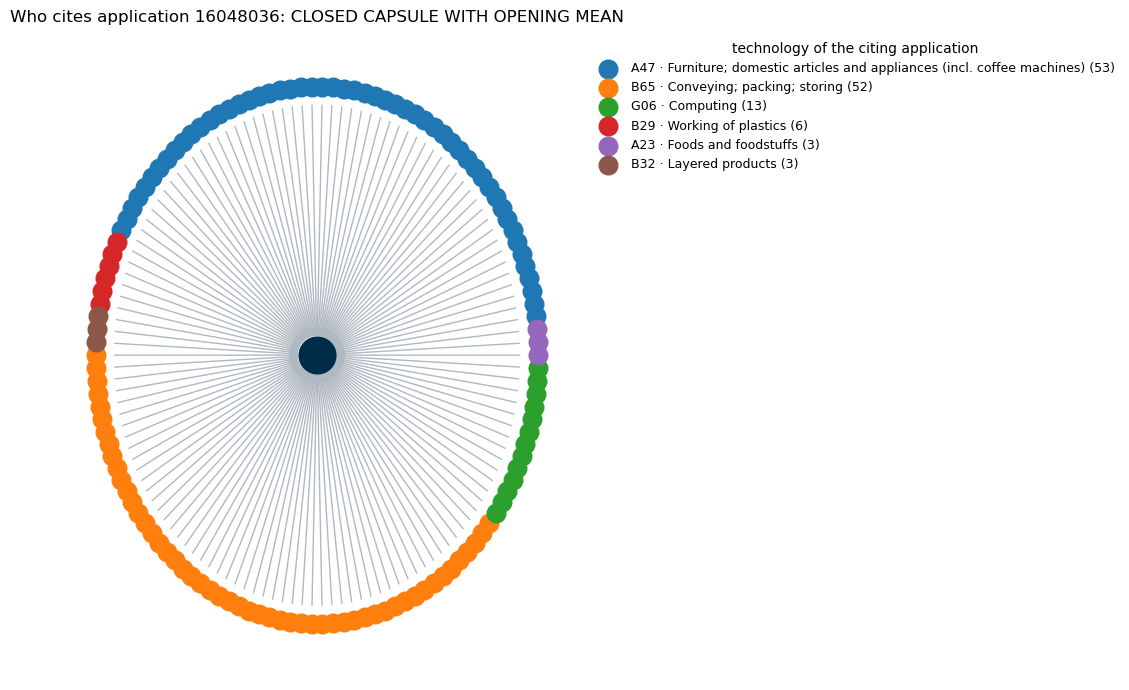

In [24]:
# The cited application at the centre; the citing ones on a circle, grouped by CPC class
citers = citers.sort_values("cpc3")
classes = list(citers.cpc3.value_counts().index)
class_colour = {c: plt.cm.tab10(k % 10) for k, c in enumerate(classes)}

S = nx.DiGraph()
S.add_edges_from((c, star) for c in citers.citing_appln_id)
ring = nx.circular_layout(citers.citing_appln_id.tolist())
spos = {**ring, star: (0, 0)}

fig, ax = plt.subplots(figsize=(11, 7))
nx.draw_networkx_edges(S, spos, ax=ax, edge_color="#B0B8C1", arrowsize=12, node_size=700)
nx.draw_networkx_nodes(S, spos, ax=ax, nodelist=[star], node_color="#002B49", node_size=700)
for c in classes:
    members = citers.loc[citers.cpc3 == c, "citing_appln_id"].tolist()
    nx.draw_networkx_nodes(S, spos, ax=ax, nodelist=members, node_color=[class_colour[c]], node_size=180,
                           label=f"{c} · {CPC_CLASS.get(c, 'CPC class ' + c)} ({len(members)})")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=9, frameon=False, title="technology of the citing application")
ax.set_title(f"Who cites application {star}: {str(title_of.get(star, ''))[:70]}")
ax.axis("off")
plt.tight_layout()
plt.show()

### 8.2 How soon does the first citation arrive?

For each application of the sector, we take the **first** EP publication that cites it and count the days from the filing date of the cited application. Then we average by filing year: "patents filed in 2005 receive their first citation, on average, N days after filing".

Read the recent years with care: a patent filed in 2020 can only have been cited quickly, because there has not been time for slow citations yet (the **truncation** problem of the lecture). Look also at the share of patents cited at all.

The table starts from **all** the applications of our sample: those never cited by an EP publication count in the share, but they have no "days to the first citation", so the averages use only the cited ones. The cell prints the three numbers.

Applications in our sample:                 1,410
... cited at least once by an EP publication: 340
... used in the averages (valid days):        340


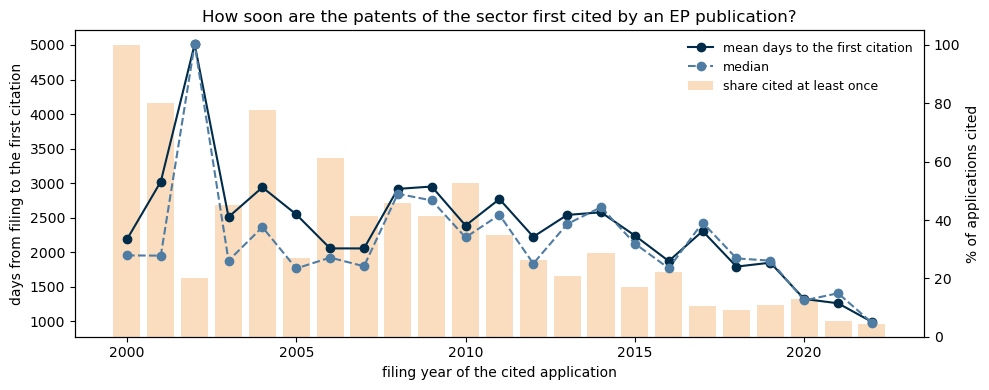

,applications,share_cited,mean_days,median_days
appln_filing_year,,,,
2000,4,1.00,2186.00,1954.0
2001,5,0.80,3022.00,1951.0
2002,5,0.20,5010.00,5010.0
2003,20,0.45,2510.22,1878.0
2004,18,0.78,2939.29,2364.0
2005,26,0.27,2547.86,1765.0
2006,18,0.61,2055.73,1923.0
2007,46,0.41,2055.37,1797.0
2008,48,0.46,2917.14,2846.0


In [25]:
first = fwd.groupby("cited_appln_id").citing_date.min().rename("first_citation")
lag = ep.set_index("appln_id")[["appln_filing_date", "appln_filing_year"]].join(first, how="left")
lag["days_to_first_citation"] = (lag.first_citation - lag.appln_filing_date).dt.days
lag.loc[lag.days_to_first_citation < 0, "days_to_first_citation"] = None   # cited before filing: data error

print(f"Applications in our sample:                 {len(lag):,}")
print(f"... cited at least once by an EP publication: {lag.first_citation.notna().sum():,}")
print(f"... used in the averages (valid days):        {lag.days_to_first_citation.notna().sum():,}")

by_year = lag.groupby("appln_filing_year").agg(
    applications=("appln_filing_date", "size"),
    share_cited=("first_citation", lambda s: s.notna().mean()),
    mean_days=("days_to_first_citation", "mean"),
    median_days=("days_to_first_citation", "median"),
)

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(by_year.index, by_year.mean_days, marker="o", color="#002B49", label="mean days to the first citation")
ax1.plot(by_year.index, by_year.median_days, marker="o", ls="--", color="#4F7CA3", label="median")
ax1.set_xlabel("filing year of the cited application")
ax1.set_ylabel("days from filing to the first citation")
ax2 = ax1.twinx()
ax2.bar(by_year.index, by_year.share_cited * 100, color="#EF7B00", alpha=0.25, label="share cited at least once")
ax2.set_ylabel("% of applications cited")
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=9, frameon=False)
ax1.set_title("How soon are the patents of the sector first cited by an EP publication?")
plt.tight_layout()
plt.show()

by_year.round(2)

## 9. Citations to science: non-patent literature (`TLS214_NPL_PUBLN`)

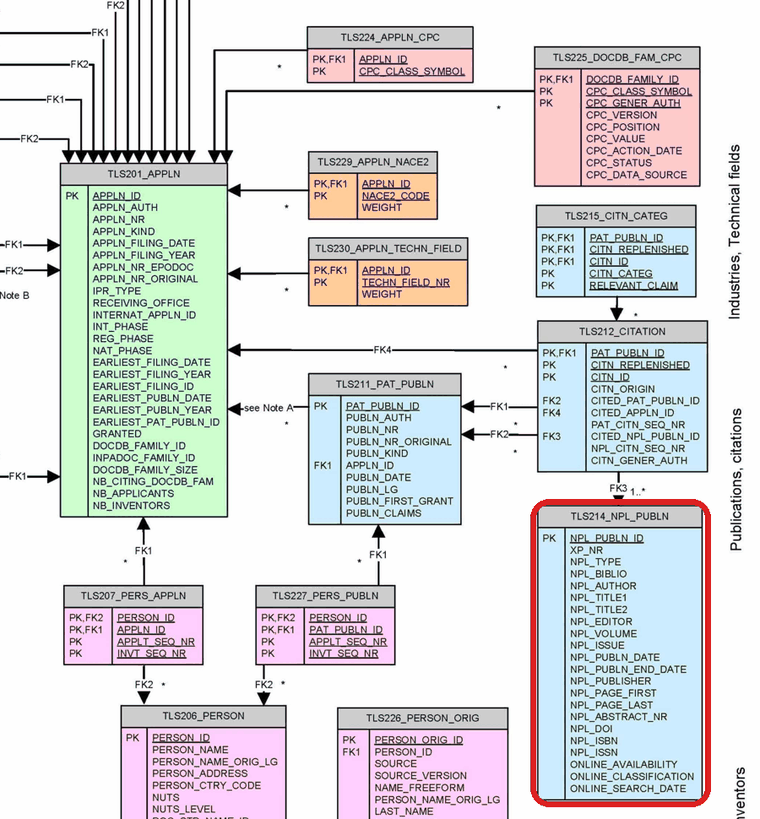

*TLS214_NPL_PUBLN: one row per cited non-patent document, reached through cited_npl_publn_id in TLS212.*

Patents also cite **non-patent literature** (NPL): scientific articles, books, standards, web pages. These references are our window on the flow of knowledge from science to technology. The bibliographic string `npl_biblio` is always there; the structured fields (author, title, DOI...) are filled to a degree that depends on `npl_type`:

| `npl_type` | Kind of document |
|---|---|
| `s` | serial: journal article, periodical |
| `b` | book |
| `a` | abstract of no specific kind (a "poor" citation, unstructured) |
| `w` | world wide web / internet search |
| `d`, `e` | Derwent or database citation |
| `c`, `i`, `j` | Chemical, Biological abstracts, Patent Abstracts of Japan |

In [26]:
q = in_sample(
    db.query(
        TLS211_PAT_PUBLN.appln_id.label("citing_appln_id"),
        TLS212_CITATION.citn_origin,
        TLS214_NPL_PUBLN.npl_publn_id,
        TLS214_NPL_PUBLN.npl_type,
        TLS214_NPL_PUBLN.npl_doi,
        TLS214_NPL_PUBLN.npl_publn_date,
        TLS214_NPL_PUBLN.npl_biblio,
    )
    .select_from(TLS211_PAT_PUBLN)
    .join(TLS212_CITATION, TLS212_CITATION.pat_publn_id == TLS211_PAT_PUBLN.pat_publn_id)
    .join(TLS214_NPL_PUBLN, TLS214_NPL_PUBLN.npl_publn_id == TLS212_CITATION.cited_npl_publn_id)
    .filter(TLS212_CITATION.cited_npl_publn_id != "0"),       # in TIP this id is text: "0" = no NPL
    TLS211_PAT_PUBLN.appln_id,
).distinct()
npl = patstat.df(q)
npl = npl[~npl.npl_publn_id.astype(str).str.strip().isin(["", "0"])]   # drop empty references, if any

print(f"NPL citations: {len(npl):,}, made by {npl.citing_appln_id.nunique():,} of {len(ep):,} EP applications")
print(f"Share of patent citations vs NPL: {len(back) / (len(back) + len(npl)):.0%} patents, "
      f"{len(npl) / (len(back) + len(npl)):.0%} NPL")
print(f"NPL with a DOI: {(npl.npl_doi.fillna('').str.strip() != '').mean():.1%}")
print(npl.npl_type.value_counts())
npl[npl.npl_type == "s"].npl_biblio.head(5).tolist()

NPL citations: 375, made by 118 of 1,410 EP applications
Share of patent citations vs NPL: 97% patents, 3% NPL
NPL with a DOI: 15.5%
npl_type
s    171
w    119
b     42
a     26
d     11
e      5
j      1
Name: count, dtype: int64


["PERVEZ T. ET AL: 'Effect of exposure on material response of a swelling elastomer', ARCHIVES OF MATERIALS SCIENCE AND ENGINEERING, vol. 37, no. 2, June 2009 (2009-06-01), pages 77 - 84",
 "HENI B. WIJAYANTI ET AL: 'Stability of Whey Proteins during Thermal Processing: A Review : Thermal stability of whey proteins...', COMPREHENSIVE REVIEWS IN FOOD SCIENCE AND FOOD SAFETY, vol. 13, no. 6, 20 October 2014 (2014-10-20), US, pages 1235 - 1251, XP055552109, ISSN: 1541-4337, DOI: 10.1111/1541-4337.12105",
 "'Nespresso', WIKIPEDIA, 29 November 2012 (2012-11-29), XP055555064",
 'R. LIPPMANN ET AL., VERPACKUNGSTECHNIK, 1985, Leipzig',
 "ANONYMOUS: 'Spezifikation Bachmann Forming AG PP EVOH PP PEPL schwarz 1.20*458 mm', ALMA, 30 September 2019 (2019-09-30), pages 1"]

### 9.1 How much science, and how old?

As for forward citations, we look at the time dimension: by filing year, the share of the sector's applications that cite at least one non-patent document, and the **age** of what they cite: the filing year of the patent minus the publication year of the cited document. A short lag means the sector uses fresh knowledge.

The structured field `npl_publn_date` is often **empty**. Before using it we check how often it is there; when it is missing we look for the year in the bibliographic string `npl_biblio`, which usually contains the date, e.g. `1 January 2005 (2005-01-01)`.

NPL citations:                         375
... with a year in npl_publn_date:     85%
... with a year after the biblio check: 90%


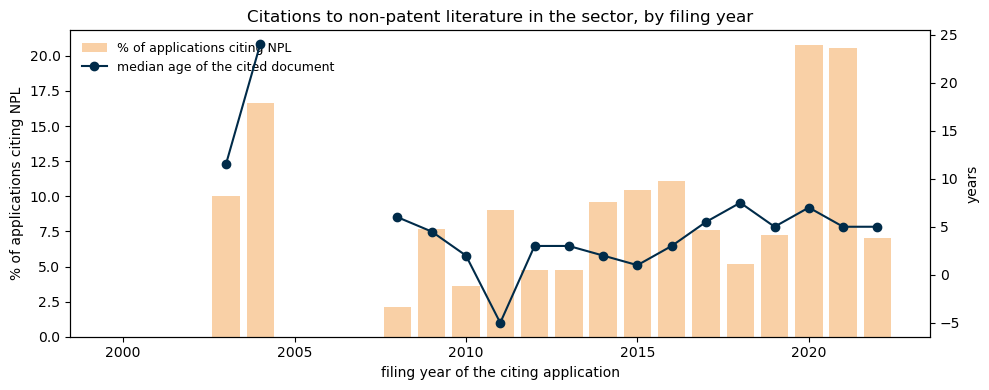

,applications,share_citing_npl,npl_with_year,median_age_years
appln_filing_year,,,,
2000,4,0.00,NaN,NaN
2001,5,0.00,NaN,NaN
2002,5,0.00,NaN,NaN
2003,20,0.10,2.0,11.5
2004,18,0.17,4.0,24.0
2005,26,0.00,NaN,NaN
2006,18,0.00,NaN,NaN
2007,46,0.00,NaN,NaN
2008,48,0.02,4.0,6.0


In [27]:
# Year of the cited document: from npl_publn_date, otherwise from the bibliographic string
year_field = pd.to_numeric(npl.npl_publn_date.astype(str).str.strip().str[:4], errors="coerce")
year_field = year_field.where(year_field.between(1900, 2030))
year_biblio = pd.to_numeric(npl.npl_biblio.str.extract(r"\((19\d{2}|20\d{2})-\d{2}-\d{2}\)")[0], errors="coerce")
year_any = pd.to_numeric(npl.npl_biblio.str.extract(r"\b(19\d{2}|20[0-2]\d)\b")[0], errors="coerce")
npl["npl_year"] = year_field.fillna(year_biblio).fillna(year_any)

print(f"NPL citations:                         {len(npl):,}")
print(f"... with a year in npl_publn_date:     {year_field.notna().mean():.0%}")
print(f"... with a year after the biblio check: {npl.npl_year.notna().mean():.0%}")

npl = npl.merge(ep[["appln_id", "appln_filing_year"]], left_on="citing_appln_id", right_on="appln_id", how="left")
npl["age_years"] = npl.appln_filing_year - npl.npl_year

science = pd.DataFrame({
    "applications": ep.groupby("appln_filing_year").appln_id.size(),
    "share_citing_npl": ep.groupby("appln_filing_year").appln_id.apply(lambda s: s.isin(npl.citing_appln_id).mean()),
    "npl_with_year": npl.groupby("appln_filing_year").npl_year.count(),
    "median_age_years": npl.groupby("appln_filing_year").age_years.median(),
})

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(science.index, science.share_citing_npl * 100, color="#EF7B00", alpha=0.35, label="% of applications citing NPL")
ax1.set_ylabel("% of applications citing NPL")
ax1.set_xlabel("filing year of the citing application")
ax2 = ax1.twinx()
ax2.plot(science.index, science.median_age_years, marker="o", color="#002B49", label="median age of the cited document")
ax2.set_ylabel("years")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9, frameon=False)
ax1.set_title("Citations to non-patent literature in the sector, by filing year")
plt.tight_layout()
plt.show()

science.round(2)

We use the **median** age: a few very old references (a 1950s handbook) would pull the mean up. A negative age means the cited document was published after the filing date: it was added later, during search or examination, and the inventors could not have used it. Years with few dated documents (`npl_with_year`) are not reliable.

Coffee capsules are a **mechanical** sector: they rely little on science, and most of their NPL is product literature and web pages. In biotech, chemistry or AI the share of journal articles is far higher. Where a DOI is available, the article can be linked to bibliographic databases such as OpenAlex. Doing this for every patent in the world is exactly what *Reliance on Science* does (section 10.3).

## 10. Other sources of citation data

PATSTAT is the raw material. Three datasets have already done much of the work above for **all** patents, and are free for research. The two OECD datasets cover **EP and US patents** (and PCT). Link: https://webfs-sti.oecd.org/files/STI-PIE/IP_DATA/2026_2/OECD%20Patent%20Databases%20-%20August%202026.pdf

### 10.1 OECD Citations database (August 2026)

Built by the OECD from PATSTAT Global Spring 2026 (`TLS212`, `TLS215`, `TLS214`, with `TLS201` and `TLS211`). Every document carries the PATSTAT `appln_id`, so it joins directly with our queries. Files are text, columns separated by `|`.

| File | What one row is |
|---|---|
| `EPO_CITATIONS` | a citation made by an EP publication (from 1978): citing and cited publication, `Citing_appln_id`, `Cited_appln_id`, `Citn_Origin`, `Citn_Category`, citation lag in years and months, Euro-PCT flag |
| `EPO_NPL_CITATIONS` | a citation of non-patent literature by an EP publication, with the full NPL string, cleaned of duplicates and of database references |
| `EPO_CIT_COUNTS` | one EP patent, with ready-made counts: backward citations (`EP_Pat_Cits`, `EP_NPL_Cits`, X citations), forward citations received as EP, as WO and **as equivalents** (`Total_cits_Recd`), and within 3 years (`Total_cits_Recd_in3`) |
| `EPO_Equivalent` | the EP equivalents of each cited patent: it catches the citations that reach the WO or US publication of the same invention |
| `PCT_…`, `USPTO_…` | the same for PCT filings and US grants (US: backward citations of grants only) |

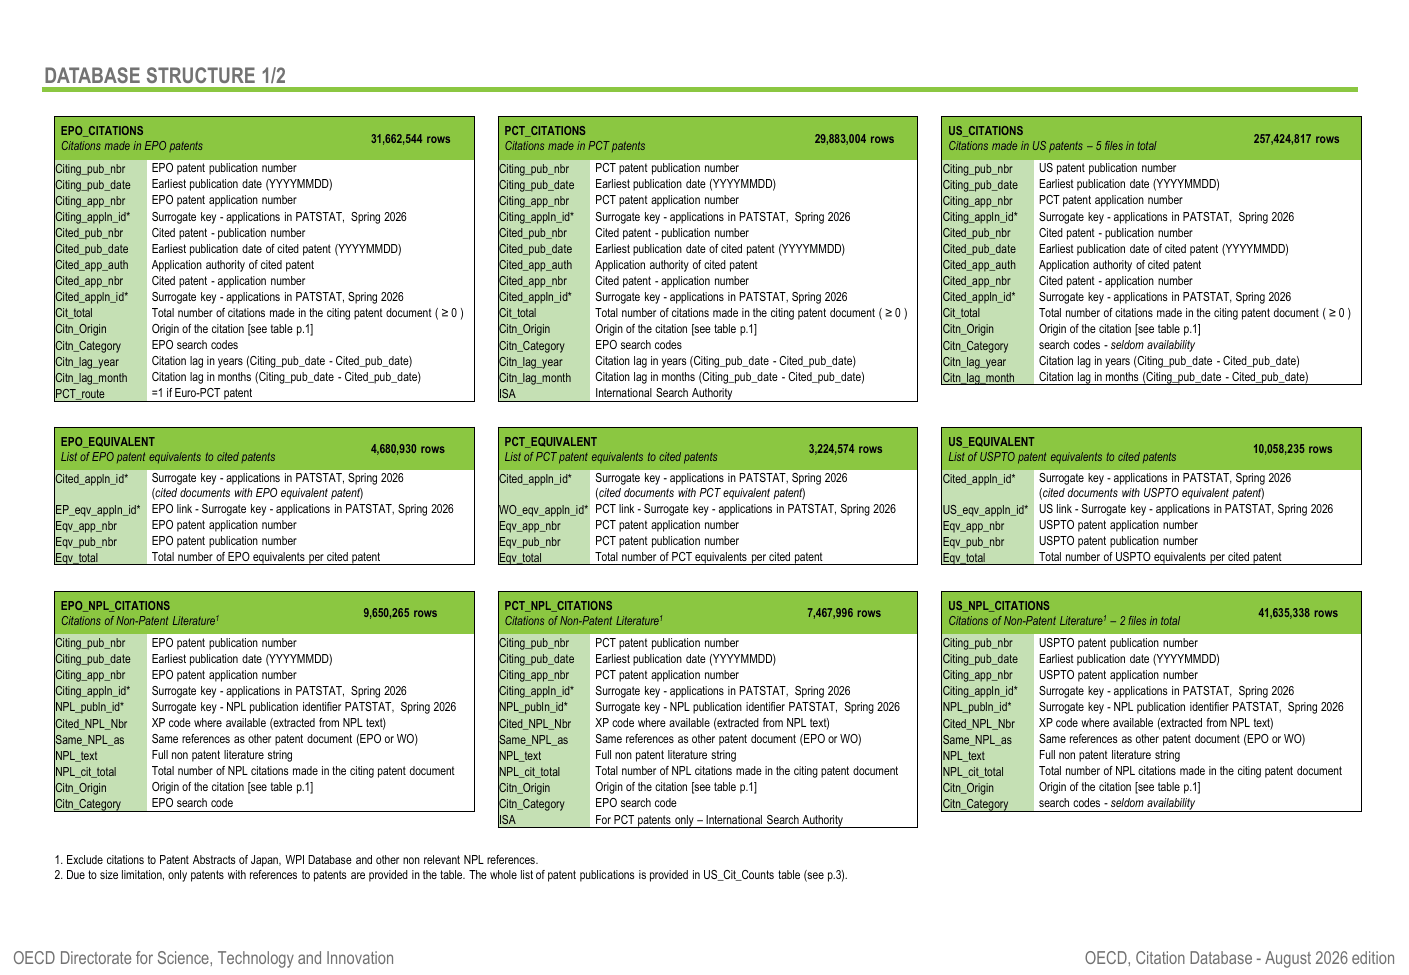

*OECD Citations database, August 2026: structure of the files (1/2).*

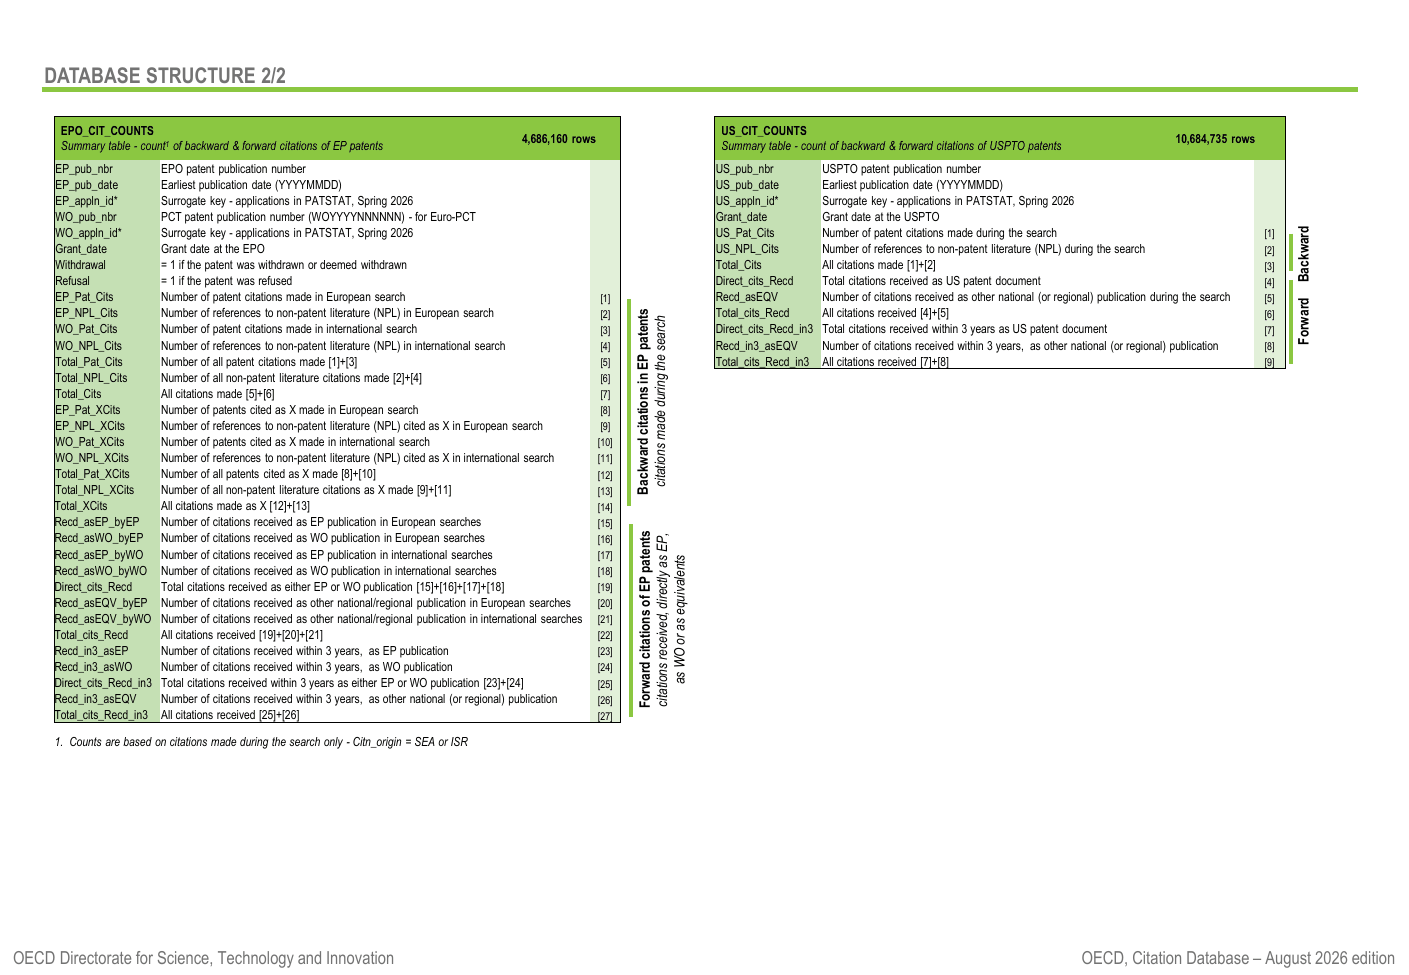

*OECD Citations database, August 2026: structure of the files (2/2), the summary counts.*

Note: the counts in `EPO_CIT_COUNTS` use only search citations (`SEA` and `ISR`), as we discussed for the EPO.

Cite as: OECD, *Citations database*, August 2026. Documentation: *OECD Citations Database – August 2026* and Webb et al. (2005), *Analysing European and International Patent Citations: A Set of EPO Patent Database Building Blocks*, OECD STI Working Paper 2005/9. Downloads and updates: [oe.cd/ipstats](https://oe.cd/ipstats).

### 10.2 OECD Patent Quality Indicators (August 2026)

One row per EP (or US) patent with indicators computed from PATSTAT with the methods of Squicciarini, Dernis and Criscuolo (2013). Each row carries the PATSTAT `appln_id`, so you can add the indicators to your sector with one join. Files: `202608_OECD_PATENT_QUALITY_EPO` and `202608_OECD_PATENT_QUALITY_USPTO`.

For now we use only its **citation counts**: the **forward citations** received within 5 and 7 years (also counting only X and Y citations), the **backward citations** and the citations to **non-patent literature**. The other indicators of the file, such as originality, generality, family size, claims and the quality index, come back in the lecture on **patent value**.

Cite as: OECD, *Patent Quality Indicators database*, August 2026; Squicciarini, M., Dernis, H. and Criscuolo, C. (2013), *Measuring Patent Quality: Indicators of Technological and Economic Value*, OECD Science, Technology and Industry Working Papers 2013/03.

### 10.3 Patent-to-paper citations: *Reliance on Science* (Marx and Fuegi)

Matt Marx and Aaron Fuegi have linked patents to the **scientific articles** they cite, both on the front page and in the text of the patent. Each link has a **confidence score** from 1 to 10, a flag for applicant or examiner citations, and says where the reference was found (front page, body text, or both). Articles are identified by their **OpenAlex** id, so you can follow each article to its authors, institutions, fields and its own citations.

- Website and documentation: [relianceonscience.org/patent-to-paper-citations](https://relianceonscience.org/patent-to-paper-citations/)
- Current data (July 2026): **USPTO** patents, citations with confidence ≥ 4, up to patents granted in 2025: [`pcs_oa_uspto.csv`](https://zenodo.org/records/21493744/files/pcs_oa_uspto.csv?download=1)
- Earlier release with **worldwide front-page** citations, including EP patents: [zenodo.org/records/11461587](https://zenodo.org/records/11461587)
- Documentation (PDF): [Reliance on Science 2024](https://zenodo.org/records/11300543/files/__relianceonscience2024.pdf?download=1)
- Code (MIT licence): [github.com/relianceonscience/ros](https://github.com/relianceonscience/ros). Data licence: CC BY-NC 4.0.

For EP patents, the front-page links of the worldwide release are the counterpart of the `TLS214` citations we collected, already matched to articles. The in-text citations exist only for US patents.